#  Ejercicio 2: Pronóstico de PM_Dongsi con una red LSTM



En el Ejercicio 1 entrenamos una RNN simple para pronosticar la contaminación PM2.5 en Nongzhanguan. Ahora repetiremos la misma metodología, pero con un modelo más potente: una red LSTM (*Long Short-Term Memory*), aplicada a la serie `PM_Dongsi` que es otro distrito de Pekín.

Seguiremos la **estrategia de ajuste de parámetros**:

1. Empezar con un modelo base sencillo (pocas unidades y pocas épocas).
2. Ir aumentando complejidad poco a poco (unidades y épocas) hasta que las predicciones nos satisfagan.
3. Pero, sin que sea modelo demasiado grande dado que se entrena muy lento y sobreajusta en vez de generalizar.



> Nota
Dado que las LSTM tardan significativamente más en entrenar que las RNN simples se activa la GPU en Colab: Entorno de ejecución → Cambiar tipo de entorno → GPU.


## Parámetros del ejercicio

| Parámetro | Valor | Significado |
|---|---|---|
| `series_days` | **50** | Últimos 50 días de la serie (1200 horas) |
| `input_hours` | **12** | La red "ve" 12 horas para predecir la siguiente |
| `test_hours` | **48** | 48 h reservadas al final: 12 de arranque + **36 h a pronosticar** |

In [1]:
# cargamos el data set
try:
    from google.colab import files
    print("Selecciona el archivo 'Appendix 2 - Beijing.csv':")
    uploaded = files.upload()   # abre el selector de archivos
    print("Archivos cargados:", list(uploaded.keys()))
except ImportError:
    print("No estás en Colab: asegúrate de tener el CSV en la misma carpeta que el notebook.")


Selecciona el archivo 'Appendix 2 - Beijing.csv':


Saving Appendix 2 - Beijing.csv to Appendix 2 - Beijing.csv
Archivos cargados: ['Appendix 2 - Beijing.csv']


# 1 — Cargar y limpiar los datos (serie PM_Dongsi)

Acá los pasos son casi idénticos a los del Ejercicio 1, solo cambia la columna:

1. Leemos el CSV con pandas.
2. Filtramos el año 2015 que son los datos más recientes.
3. Contamos los valores faltantes (`NaN`) y los rellenamos con **interpolación lineal**: pandas une con una línea recta el valor anterior y el posterior de cada hueco.
4. Dibujamos los últimos 42 días para sentir los datos (42 × 24 = 1008 horas).




In [2]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM   # ← novedad: capa LSTM

# Semillas para reproducibilidad (mismos resultados en cada ejecución)
np.random.seed(42)
tf.random.set_seed(42)

print("Versión de tensorflow:", tf.__version__)
print("¿Hay GPU disponible?:", len(tf.config.list_physical_devices('GPU')) > 0)


Versión de tensorflow: 2.21.0
¿Hay GPU disponible?: False


In [3]:
# Cargamos el archivo CSV
df_Beijing = pd.read_csv('Appendix 2 - Beijing.csv')

#  Solo datos del año 2015 (año completo = 8760 filas horarias)
df_Beijing = df_Beijing[df_Beijing.year >= 2015].copy()
print("Tamaño del dataset (filas, columnas):", df_Beijing.shape)

#  Contamos los valores faltantes de la serie que usaremos
n_faltantes = df_Beijing['PM_Dongsi'].isna().sum()
print(f"Valores faltantes (NaN) en PM_Dongsi: {n_faltantes}")

#  Interpolamos: rellenamos los huecos con líneas rectas entre valores conocidos
df_Beijing['PM_Dongsi'] = df_Beijing['PM_Dongsi'].interpolate()
print("Después de interpolar, faltantes:", df_Beijing['PM_Dongsi'].isna().sum())

df_Beijing.head(8)


Tamaño del dataset (filas, columnas): (8760, 18)
Valores faltantes (NaN) en PM_Dongsi: 164
Después de interpolar, faltantes: 0


,No,year,month,day,hour,season,PM_Dongsi,PM_Dongsihuan,PM_Nongzhanguan,PM_US Post,DEWP,HUMI,PRES,TEMP,cbwd,Iws,precipitation,Iprec
43824,43825,2015,1,1,0,4,5.0,32.0,8.0,22.0,-21.0,29.0,1034.0,-6.0,SE,0.89,0.0,0.0
43825,43826,2015,1,1,1,4,4.0,12.0,7.0,9.0,-22.0,23.0,1034.0,-4.0,NW,4.92,0.0,0.0
43826,43827,2015,1,1,2,4,3.0,19.0,7.0,9.0,-21.0,27.0,1034.0,-5.0,NW,8.94,0.0,0.0
43827,43828,2015,1,1,3,4,4.0,9.0,11.0,13.0,-21.0,29.0,1035.0,-6.0,NW,12.96,0.0,0.0
43828,43829,2015,1,1,4,4,3.0,11.0,5.0,10.0,-21.0,27.0,1034.0,-5.0,NW,16.98,0.0,0.0
43829,43830,2015,1,1,5,4,3.0,18.0,3.0,6.0,-22.0,23.0,1034.0,-4.0,NW,24.13,0.0,0.0
43830,43831,2015,1,1,6,4,3.0,20.0,6.0,8.0,-23.0,22.0,1034.0,-5.0,NW,25.92,0.0,0.0
43831,43832,2015,1,1,7,4,3.0,22.0,7.0,17.0,-22.0,26.0,1035.0,-6.0,SE,1.79,0.0,0.0


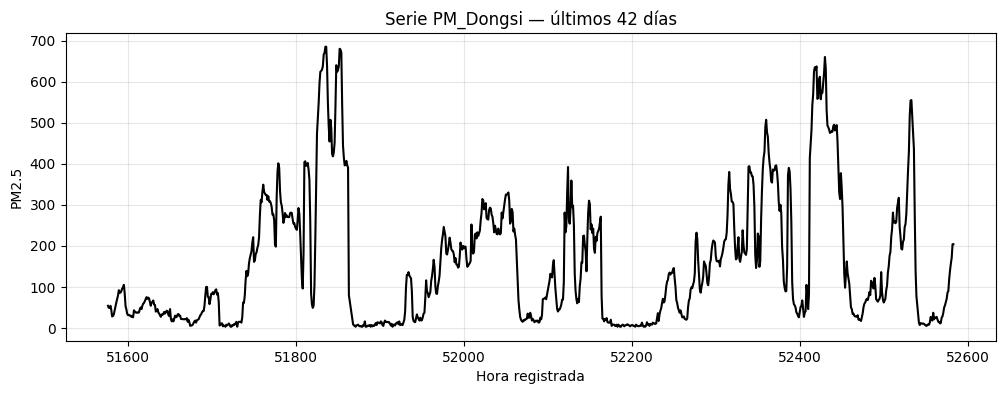

In [4]:
def get_n_last_days(df, series_name, n_days):
    """Devuelve los últimos n_days días (horas) de una serie."""
    return df[series_name][-(24 * n_days):]

def plot_n_last_days(df, series_name, n_days):
    """Dibuja los últimos n_days días de una serie horaria."""
    plt.figure(figsize=(12, 4))
    plt.plot(get_n_last_days(df, series_name, n_days), 'k-')
    plt.title('Serie {} — últimos {} días'.format(series_name, n_days))
    plt.xlabel('Hora registrada')
    plt.ylabel('PM2.5')
    plt.grid(alpha=0.3)
    plt.show()

# Gráfica de los últimos 42 días
plot_n_last_days(df_Beijing, 'PM_Dongsi', 42)


# 2 — Preparar los datos: ventana deslizante (repaso rápido)

Usamos la misma técnica que en el Ejercicio 1. La convertimos en muchos ejemplos entrada → objetivo con una ventana que se desliza por la serie:

```
entrada = 12 horas consecutivas  →  objetivo = valor de la hora siguiente
```

- De los últimos 50 días (1200 h) reservamos las últimas 48 h para el test.
- El entrenamiento avanza de 3 en 3 horas (`sample_gap = 3`) generando ventanas.
- Keras recibe los datos con forma (n_ejemplos, 12 pasos, 1 variable).

```
[──────── 1152 h de ENTRENAMIENTO ────────][── 48 h de TEST ──]
                                           ↑ 12 h de arranque + 36 h a predecir
```


In [8]:
def get_keras_format_series(series):
    """Convierte ventanas en arreglo numpy de forma (n_ejemplos, pasos, 1)."""
    series = np.array(series)
    return series.reshape(series.shape[0], series.shape[1], 1)

def get_train_test_data(df, series_name, series_days, input_hours,
                        test_hours, sample_gap=3):

    forecast_series = get_n_last_days(df, series_name, series_days).values

    train = forecast_series[:-test_hours]
    test  = forecast_series[-test_hours:]

    train_X, train_y = [], []
    for i in range(0, train.shape[0] - input_hours, sample_gap):
        train_X.append(train[i:i + input_hours])
        train_y.append(train[i + input_hours])

    train_X = get_keras_format_series(train_X)
    test_X_init = test[:input_hours]
    test_y      = test[input_hours:]

    return train_X, test_X_init, train_y, test_y





In [9]:
# ── Parámetros EXACTOS del ejercicio 2 ────────────────────────
series_days = 50     # últimos 50 días de la serie
input_hours = 12     # la red "ve" 12 horas
test_hours  = 48     # 48 h al final (12 arranque + 36 a predecir)

train_X, test_X_init, train_y, test_y = get_train_test_data(
    df_Beijing, 'PM_Dongsi', series_days, input_hours, test_hours)

print("Forma de train_X   :", train_X.shape)
print("Forma de test_X_init:", test_X_init.shape)
print("Longitud de test_y  :", len(test_y), "horas reales a pronosticar")
print()
print("Primer ejemplo de entrenamiento:")
print("  entrada (12 h):", train_X[0].flatten())
print("  objetivo (h+1):", train_y[0])

Forma de train_X   : (380, 12, 1)
Forma de test_X_init: (12,)
Longitud de test_y  : 36 horas reales a pronosticar

Primer ejemplo de entrenamiento:
  entrada (12 h): [125. 132. 129. 137. 102.  97.  98. 120. 123. 123. 172. 198.]
  objetivo (h+1): 204.0


# 3 — Una LSTM

## para la RNN simple

Una RNN simple guarda un solo resumen de lo que ha visto. Problema: con secuencias largas, ese resumen se diluye — la red olvida lo que pasó hace muchos pasos (el problema del desvanecimiento del gradiente).
https://es.wikipedia.org/wiki/Problema_de_desvanecimiento_de_gradiente

## La LSTM: una memoria con compuertas

La LSTM (Long Short-Term Memory) soluciona esto con una celda de memoria protegida por tres compuertas que aprenden qué guardar, qué tirar y qué mostrar:

| Compuerta | Analogía | ¿Qué decide? |
|---|---|---|
| Olvido (forget) |  ¿Qué recuerdos borro? | Qué información antigua ya no sirve |
| Entrada (input) |  ¿Qué guardo? | Qué información nueva vale la pena recordar |
| Salida (output) |  ¿Qué muestro? | Qué parte de la memoria usar para la predicción |

Gracias a esto, la LSTM puede recordar patrones de hace muchas horas mucho mejor que la RNN simple, y por eso suele dar predicciones que siguen mejor la forma de la curva real (anticipa cambios de tendencia, no solo extrapola).

## El precio: más parámetros y más tiempo

Cada unidad LSTM tiene ~4 veces más pesos que una unidad RNN simple (necesita una red de pesos para cada compuerta). Consecuencias:

-  Entrenamiento más lento
-  Más riesgo de sobreajuste — más parámetros = más capacidad de memorizar.


In [10]:
# Función de entrenamiento (LSTM)
def fit_LSTM(train_X, train_y, cell_units, epochs, batch_size=64,
             validation_split=0.1):

    model = Sequential()
    model.add(LSTM(cell_units,                              # ← la capa LSTM
                   input_shape=(train_X.shape[1], 1)))       # (12 pasos, 1 variable)
    model.add(Dense(1))                                      # salida: 1 número

    model.compile(loss='mean_squared_error', optimizer='adam')
    history = model.fit(train_X, np.array(train_y),
                        epochs=epochs,
                        batch_size=batch_size,
                        validation_split=validation_split,
                        verbose=0)
    return model, history

In [11]:
# Pronóstico paso a paso similiar al ej.1
def predict(X_init, n_steps, model):
    """
    Genera n_steps predicciones de forma ITERATIVA:
    predice la hora siguiente → desplaza la ventana → repite.
    """
    X_init = np.array(X_init).copy().reshape(1, -1, 1)
    preds = []

    for _ in range(n_steps):
        pred = model.predict(X_init, verbose=0)
        preds.append(pred[0, 0])
        X_init[:, :-1, :] = X_init[:, 1:, :]
        X_init[:, -1, :]  = pred

    return np.array(preds)

In [12]:
#  Métricas de errores
def compute_metrics(y_true, y_pred):
    y_true = np.array(y_true).flatten()
    mae  = np.mean(np.abs(y_true - y_pred))               # Error Absoluto Medio
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))        # Raíz Error Cuadrático Medio
    return mae, rmse


In [13]:
# Pronosticar + graficar + medir
def predict_and_plot(X_init, y, model, title):
    y_preds = predict(X_init, n_steps=len(y), model=model)
    y_true  = np.array(y).flatten()
    mae, rmse = compute_metrics(y_true, y_preds)

    start_range   = range(1, input_hours + 1)
    predict_range = range(input_hours, test_hours)

    plt.figure(figsize=(10, 4))
    plt.plot(start_range,   np.array(X_init).flatten(), 'k-',  label='Arranque (12 h reales)')
    plt.plot(predict_range, y_true,  color='orange',           label='Valores reales')
    plt.plot(predict_range, y_preds, color='teal', linestyle='--', label='Predicciones')
    plt.axvline(input_hours + 0.5, color='gray', linestyle=':', alpha=0.6)

    plt.title(title)
    plt.xlabel('Hora')
    plt.ylabel('PM2.5')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    print(f"  → MAE  = {mae:.2f}  µg/m³")
    print(f"  → RMSE = {rmse:.2f}  µg/m³")
    return y_preds, mae, rmse

In [14]:
# Diccionario donde guardaremos los resultados de cada configuración
results = {}

n_train = train_X.shape[0]
print(f"Ejemplos de entrenamiento: {n_train}  →  validación (10%): {int(n_train*0.1)}")


Ejemplos de entrenamiento: 380  →  validación (10%): 38


# 4 — Configuración 1: modelo base

**Hiperparámetros:** `cell_units = 10` · `epochs = 10` · `batch_size = 64`

Empezamos con lo mínimo, igual que en el Ejercicio 1, para tener una línea base con la que comparar.

 Pocas actualizaciones de pesos (10 épocas × ⌈380/64⌉ ≈ 7 lotes ≈ 70 actualizaciones en total): el modelo apenas aprenderá y probablemente dará una predicción casi plana (**subajuste**).


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


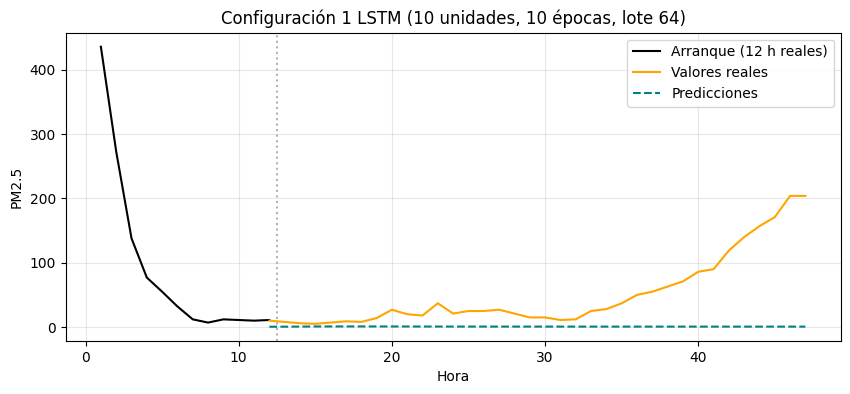

  → MAE  = 50.36  µg/m³
  → RMSE = 76.01  µg/m³


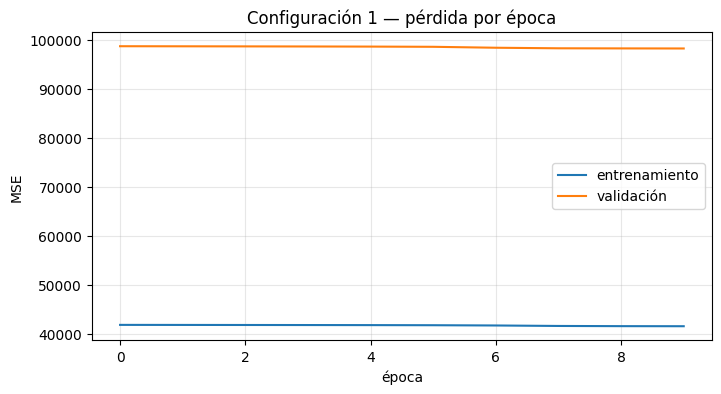

In [15]:
# Configuración 1: baseline

modelo1, historial1 = fit_LSTM(train_X, train_y,
                               cell_units=10, epochs=10, batch_size=64)

y_pred_1, mae_1, rmse_1 = predict_and_plot(
    test_X_init, test_y, modelo1,
    'Configuración 1 LSTM (10 unidades, 10 épocas, lote 64)')

results['C1: 10u / 10ép / lote64'] = (mae_1, rmse_1)

# Curvas de pérdida
plt.figure(figsize=(8, 4))
plt.plot(historial1.history['loss'], label='entrenamiento')
plt.plot(historial1.history['val_loss'], label='validación')
plt.title('Configuración 1 — pérdida por época')
plt.xlabel('época'); plt.ylabel('MSE'); plt.legend(); plt.grid(alpha=0.3)
plt.show()


# 5 Configuración 2: modelo intermedio

**Hiperparámetros:** `cell_units = 32` · `epochs = 100` · `batch_size = 32`

Aumentamos la complejidad con moderación: más memoria (32 unidades), más pasadas por los datos (100 épocas ≈ 1200 actualizaciones) y lotes más pequeños (32).

  la predicción debería seguir la forma de la curva real. Comprueba si la LSTM anticipa mejor los cambios de tendencia que la RNN simple del Ejercicio 1.


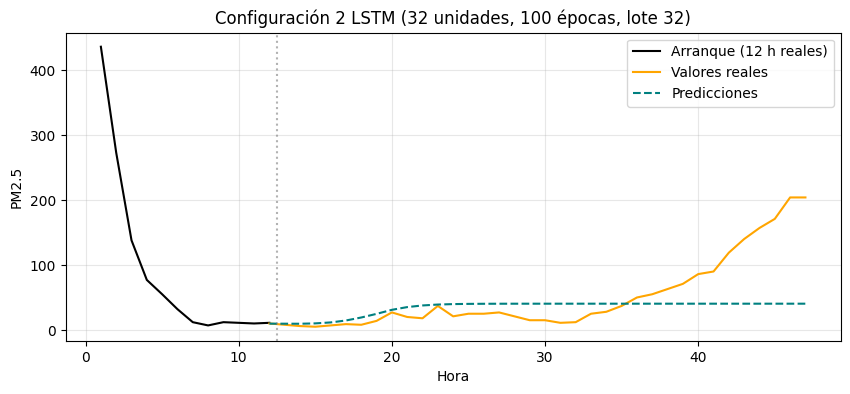

  → MAE  = 34.19  µg/m³
  → RMSE = 55.83  µg/m³


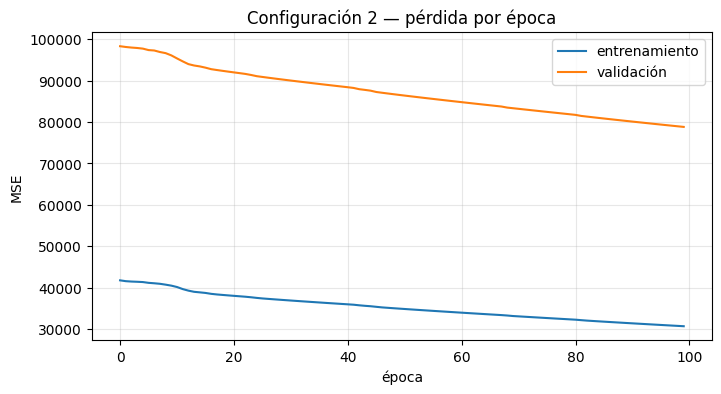

In [16]:
# Configuración 2: intermedia
modelo2, historial2 = fit_LSTM(train_X, train_y,
                               cell_units=32, epochs=100, batch_size=32)

y_pred_2, mae_2, rmse_2 = predict_and_plot(
    test_X_init, test_y, modelo2,
    'Configuración 2 LSTM (32 unidades, 100 épocas, lote 32)')

results['C2: 32u / 100ép / lote32'] = (mae_2, rmse_2)

plt.figure(figsize=(8, 4))
plt.plot(historial2.history['loss'], label='entrenamiento')
plt.plot(historial2.history['val_loss'], label='validación')
plt.title('Configuración 2 — pérdida por época')
plt.xlabel('época'); plt.ylabel('MSE'); plt.legend(); plt.grid(alpha=0.3)
plt.show()


# 6 — Configuración 3: modelo complejo (¡con cautela!)

Hiperparámetros: `cell_units = 64` · `epochs = 200` · `batch_size = 16`



1. **Tiempo**: 200 épocas con 64 unidades LSTM (y 27 lotes por época ≈ 5400 actualizaciones) tarda *claramente más* que las anteriores.
2. **Sobreajuste**: la curva de validación. Si `val_loss` sube mientras `loss` baja → la LSTM está memorizando el entrenamiento. *la LSTM sobreajusta más fácilmente que la RNN simple* por tener ~4× más pesos por unidad.




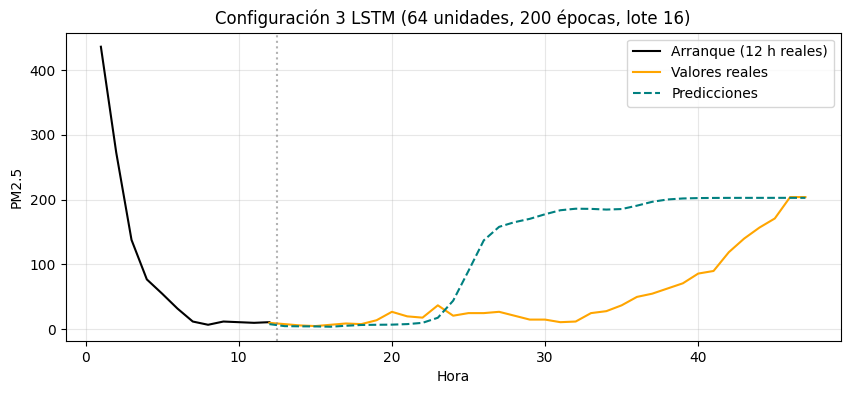

  → MAE  = 74.83  µg/m³
  → RMSE = 99.42  µg/m³


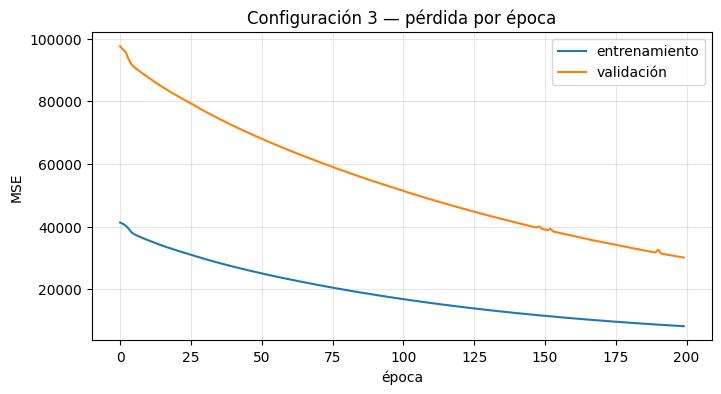

In [17]:
# Configuración 3: compleja
# celda de varios mninutos
modelo3, historial3 = fit_LSTM(train_X, train_y,
                               cell_units=64, epochs=200, batch_size=16)

y_pred_3, mae_3, rmse_3 = predict_and_plot(
    test_X_init, test_y, modelo3,
    'Configuración 3 LSTM (64 unidades, 200 épocas, lote 16)')

results['C3: 64u / 200ép / lote16'] = (mae_3, rmse_3)

plt.figure(figsize=(8, 4))
plt.plot(historial3.history['loss'], label='entrenamiento')
plt.plot(historial3.history['val_loss'], label='validación')
plt.title('Configuración 3 — pérdida por época')
plt.xlabel('época'); plt.ylabel('MSE'); plt.legend(); plt.grid(alpha=0.3)
plt.show()


# 7 — Comparación de resultados

Reunimos MAE y RMSE de las tres configuraciones y dibujamos todas las predicciones sobre los valores reales:

- **MAE** bajo = acierto típico bueno (µg/m³).
- **RMSE** bajo = sin errores catastróficos (si RMSE >> MAE, hay algunas predicciones muy desviadas; en pronósticos iterativos el error se acumula con las horas).


In [18]:
# Tabla comparativa de métricas
tabla = pd.DataFrame(results, index=['MAE', 'RMSE']).T.round(2)
tabla = tabla.sort_values('MAE')   # de mejor a peor
print("=== Comparación de configuraciones LSTM (ordenadas por MAE) ===")
tabla


=== Comparación de configuraciones LSTM (ordenadas por MAE) ===


,MAE,RMSE
C2: 32u / 100ép / lote32,34.19,55.83
C1: 10u / 10ép / lote64,50.36,76.01
C3: 64u / 200ép / lote16,74.83,99.42


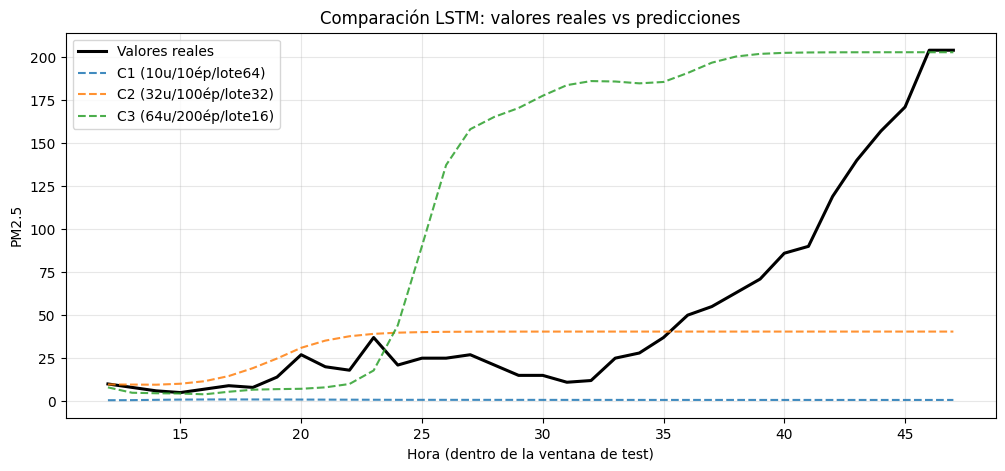

🏆 Mejor configuración según MAE: C2: 32u / 100ép / lote32
                            MAE   RMSE
C2: 32u / 100ép / lote32  34.19  55.83
C1: 10u / 10ép / lote64   50.36  76.01
C3: 64u / 200ép / lote16  74.83  99.42


In [19]:
# Gráfica comparativa: reales vs las 3 configuraciones
predict_range = range(input_hours, test_hours)

plt.figure(figsize=(12, 5))
plt.plot(predict_range, test_y, color='black', linewidth=2.2, label='Valores reales')
plt.plot(predict_range, y_pred_1, '--', alpha=0.85, label='C1 (10u/10ép/lote64)')
plt.plot(predict_range, y_pred_2, '--', alpha=0.85, label='C2 (32u/100ép/lote32)')
plt.plot(predict_range, y_pred_3, '--', alpha=0.85, label='C3 (64u/200ép/lote16)')

plt.title('Comparación LSTM: valores reales vs predicciones')
plt.xlabel('Hora (dentro de la ventana de test)')
plt.ylabel('PM2.5')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

mejor = tabla.index[0]
print("Mejor configuración según MAE:", mejor)
print(tabla)


In [20]:
# Número de parámetros entrenables (complejidad computacional)
for nombre, m in [('C1', modelo1), ('C2', modelo2), ('C3', modelo3)]:
    print(f"{nombre}: {m.count_params():,} parámetros entrenables")


C1: 491 parámetros entrenables
C2: 4,385 parámetros entrenables
C3: 16,961 parámetros entrenables


##  Análisis del impacto de los hiperparámetros

### 1. C1 → C2: de no-aprender a generalizar
- En **C1** las curvas de pérdida aún no han convergido y la predicción es casi plana → **subajuste** (modelo demasiado simple o entrenamiento muy corto).
- En **C2** las curvas de entrenamiento y validación convergen juntas: la LSTM ha captado el patrón de la serie sin memorizar → **buen equilibrio**.

### 2. Sobreajuste en C3
- Vigila la "tijera" entre las curvas: si la pérdida de **entrenamiento** sigue bajando pero la de **validación** se estanca o sube, la red memoriza las 380 ventanas de entrenamiento.
- Síntoma típico en las predicciones: empiezan razonablemente y luego se **achatan** hacia el valor medio (el modelo perdió capacidad de generalizar y se volvió conservador).

### 3. MAE vs RMSE
- **RMSE >> MAE**: hay algunas horas con error grande (la predicción iterativa acumula error al reutilizar sus propias salidas como entrada).
- Si C3 mejora el MAE pero empeora mucho el RMSE, está cometiendo errores puntuales graves a cambio de aciertos medios: normalmente **no compensa**.

### 4. Eficiencia: LSTM vs RNN simple
- Con los mismos hiperparámetros, la LSTM tiene **~4× más parámetros** y tarda más por época.

Interpretación IA Gemini


# 8 - Conclusiones y arquitectura final

## Justificación de la arquitectura seleccionada

Rellena esta plantilla con **tus resultados** (los números varían ligeramente con cada entrenamiento):

> **Arquitectura seleccionada:** *Configuración 2 (32 unidades LSTM, 100 épocas, lote 32).*
>
> **Justificación:**
> 1. **Precisión:** obtiene un MAE de ~*XX* µg/m³ y RMSE de ~*XX*, muy superior al modelo base C1 (~*XX*), que sufría subajuste.
> 2. **Generalización:** sus curvas de entrenamiento y validación **convergen juntas**, señal de buena generalización.
> 3. **Eficiencia:** alcanza prácticamente el mismo error en test que C3 con **menos parámetros y menos tiempo de entrenamiento**. C3 solo reduce la pérdida de entrenamiento (memorización) → sobreajuste, sin mejorar el pronóstico real.
> 4. **Comparación con la RNN simple (Ej. 1):** con los mismos hiperparámetros, la LSTM [mejora / apenas mejora] el pronóstico a costa de [X veces] más parámetros y tiempo. *Nota y explica si el beneficio justifica el costo.*



